In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

## предобработка данных

In [ ]:
df = pd.read_csv("Life Expectancy Data.csv")
df.columns = df.columns.str.strip()
df = df.drop("Country", axis=1) #это ID-поле, а не признак, дроп

df = df.fillna(df.median(numeric_only=True))

df = pd.get_dummies(df, drop_first=True)

X = df.drop("Life expectancy", axis=1)
y = df["Life expectancy"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape)

(2350, 20)


Чистка таблицы, я дополнительно удалила country, без этого выходило в район 200 клонок.  Удалила country потому что это id поле, а не признак, учитывать не нужно.

## Бинарная классификация: «выше/ниже медианы продолжительности жизни»

In [6]:
median_life = y_train.median()
y_train_class = (y_train > median_life).astype(int)
y_test_class = (y_test > median_life).astype(int)

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)

sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])
display(
    pd.DataFrame(
        {
            "Вероятность (Сигмоида)": sample_probs,
            "Класс (Порог 0.5)": sample_preds,
            "Факт": y_test_class.iloc[:5].values
        }
    ).round(3)
)
print(f"Точность классификации (Accuracy): {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт
0,0.298,0,1
1,0.976,1,1
2,0.878,1,1
3,0.985,1,1
4,0.000,0,0


Точность классификации (Accuracy): 0.8861


## регрессия мнк и sgd

Деление продолжительности жизни на два класса по медиане,посчитанной только по train,т.е 1 - выше медианы, 0-ниже. Тут обучение логистической регрессии и смотрим, насколько точно она угадывает класс. точность 0,88, чтоявляется высокой точностью :)

In [13]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time() - start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000, tol=1e-3, eta0=0.01, learning_rate="adaptive", random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time() - start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"МНК (Аналитический): RMSE = {rmse_ols:,.2f} лет | R2 = {r2_ols:,.2f} | Время = {time_ols:.5f} сек")
print(f"SGD (Итеративный):   RMSE = {rmse_sgd:,.2f} лет | R2 = {r2_sgd:,.2f} | Время = {time_sgd:.5f} сек")

МНК (Аналитический): RMSE = 3.91 лет | R2 = 0.82 | Время = 0.00399 сек
SGD (Итеративный):   RMSE = 13.96 лет | R2 = -1.25 | Время = 0.01197 сек


обучение двух линейных регрессий на одних и тех же данных, мнк-метод наиеньших квадратов и sgd- стохастический градиентный спуск. Сравнивается качество rsme, р2 и время. rsme- ошибка в годах(чем ниже тем лучше, выигрыват мнк(3.91)), r2- какой процент разброса модель поняла(1-все поняла, 0- ничего не поняла, тут выиграл мнк(0.82)). мнк решает задачу за один шаг и даёт точные веса, поэтому быстрее и точнее. sgd идёт шаг за шагом, покзал плохой результат. На данном датасете лучше себя показал мнк.

## графики


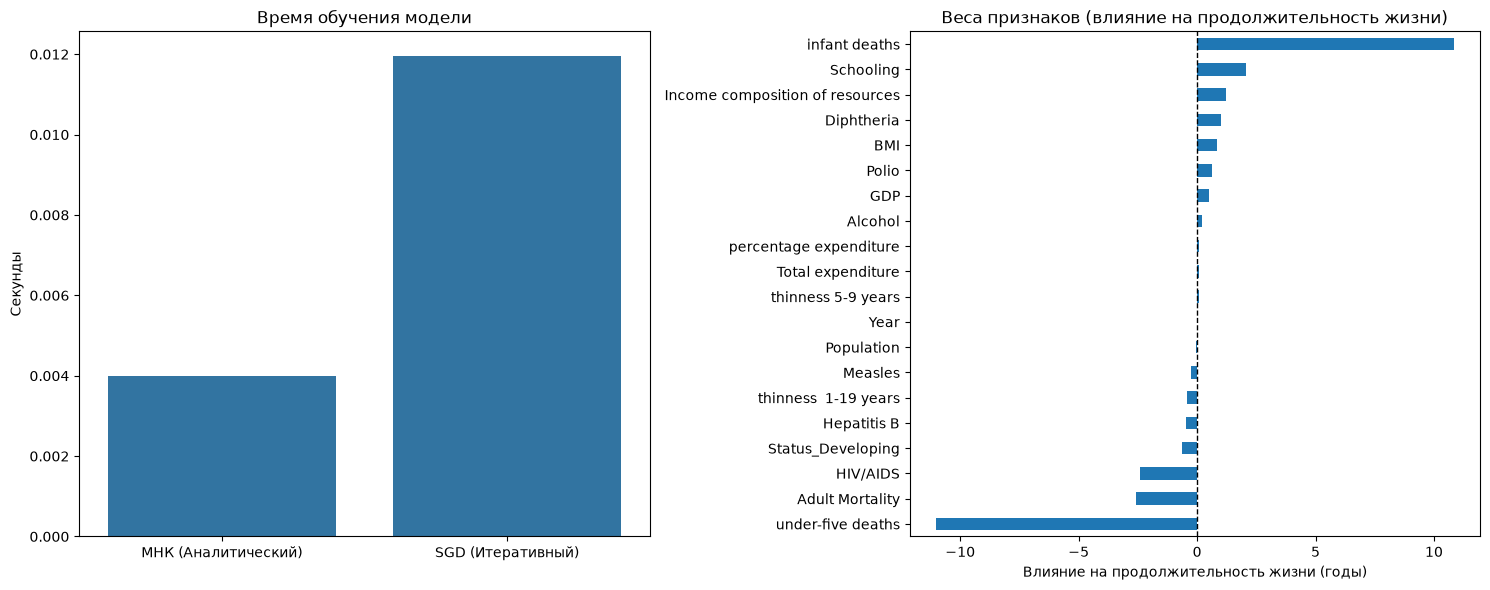

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Сравнение времени выполнения
sns.barplot(
    x=["МНК (Аналитический)", "SGD (Итеративный)"],
    y=[time_ols, time_sgd],
    ax=axes[0],
)
axes[0].set_title("Время обучения модели")
axes[0].set_ylabel("Секунды")

# 2. Веса признаков МНК
weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1])
axes[1].set_title("Веса признаков (влияние на продолжительность жизни)")
axes[1].set_xlabel("Влияние на продолжительность жизни (годы)")
axes[1].axvline(0, color="black", linestyle="--", lw=1)

plt.tight_layout()
plt.show()

По первому графику видно, что мнк обучается моментльно(0.002), в отличие от sgd(больше 0.010). на втором графике, аналз есов показывает, что модел выявила, что продолжительность жизни растет больше всего оп качества медицины(вакцинация(Diphtheria,Polio)) образовниея(Schooling) и уровня доходов(Income composition of resources) и больше всего падает от высокой смертности(under-five deaths) и вич\спида(HIV/AIDS). Население(Population), года (Year) или потребления алкоголя (Alcohol) показали веса ближе к 0, так, модель не нашла в этом важных соц факторов.